In [2]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

import torch

from convolutional_autoencoder import ConvolutionalAutoencoder, UpSampleConvolutionalBlock, ConvolutionalBlock

In [72]:
data_path = Path('').cwd().parent.parent / 'database' / 'spectra'

data_path

WindowsPath('c:/Users/alexa/OneDrive/Área de Trabalho/LineProphet-Machine-Learning-for-Spectral-Attributes/database/spectra')

In [66]:
# encoder = ConvolutionalBlock(in_channels=2, out_channels=20, kernel_size_max_pooling=2,kernel_size_conv=3,num_layers=5)

# decoder = UpSampleConvolutionalBlock(in_channels=20, out_channels = 2,kernel_size_conv=3,num_layers=3)

model = ConvolutionalAutoencoder([(2,16,2,3,5),(16,20,2,3,5)])

In [67]:
vector = torch.rand(dtype=torch.float32, size=(1,2,1000))

vector_encoded = model.encoder(vector)

vector_decoded = model.decoder(vector_encoded)

In [69]:
print(model)

ConvolutionalAutoencoder(
  (encoder_layer): Sequential(
    (0): ConvolutionalBlock(
      (conv_block): Sequential(
        (0): Conv1d(2, 16, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): GELU(approximate='none')
        (2): Conv1d(16, 16, kernel_size=(3,), stride=(1,), padding=(1,))
        (3): GELU(approximate='none')
        (4): Conv1d(16, 16, kernel_size=(3,), stride=(1,), padding=(1,))
        (5): GELU(approximate='none')
        (6): Conv1d(16, 16, kernel_size=(3,), stride=(1,), padding=(1,))
        (7): GELU(approximate='none')
        (8): Conv1d(16, 16, kernel_size=(3,), stride=(1,), padding=(1,))
        (9): GELU(approximate='none')
        (10): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvolutionalBlock(
      (conv_block): Sequential(
        (0): Conv1d(16, 20, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): GELU(approximate='none')
        (2): Conv1d(20, 20, kernel_size=(3,), stride=

In [42]:
vector.shape, vector_encoded.shape, vector_decoded.shape

(torch.Size([1, 2, 1000]), torch.Size([1, 16, 500]), torch.Size([1, 2, 1000]))

In [26]:
vector.shape

torch.Size([1, 2, 1000])

In [74]:
spectrum = list(data_path.rglob('*.npz'))

wavenumbers (69305,)
absorption (69305,)
molecule hcl
pressure_atm 0.9412482612102552
temperature_k 323.6040327130345
optical_path_cm 4.518345498956876
step 0.01
resolution 0.09364779161046041
slit_function SLIT_TRIANGULAR
convolve True
diluent_gases ['self']
diluent_fractions [1.]
wavenumber_min 5304.0504169999995
wavenumber_max 5997.090416999999
split train
index 4815


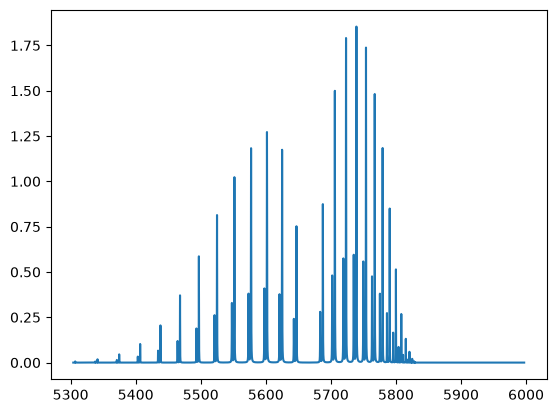

In [76]:
data = np.load(np.random.choice(spectrum))
plt.plot(data['wavenumbers'], data['absorption'])
for i in data.keys():
    if i in ['wavenumbers', 'absorption']:
        print(i, data[i].shape)

    else:
        print(i, data[i])



In [68]:
wavenumbers = data['wavenumbers']
absorption = data['absorption']

arr = np.stack([wavenumbers, absorption], axis=0)
arr = arr.astype(np.float32)

spectrum = torch.from_numpy(arr)

In [69]:
if spectrum.shape[-1] % 2 != 0:
    spectrum = spectrum[..., :-1]

In [70]:
spectrum.shape

torch.Size([2, 65888])